In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 19.6 — Braidings, balancing and ribbon duality (19.42)–(19.43)

**Source.** SMSA 7.8, 2026-11-05 (local `smsa.pdf`, SHA-256 `6922b174…813b8fe`). References are section and equation numbers of that version.

**Translation conventions.** `f >> g` is SMSA's $g\circ f$ (first $f$, then $g$); `f @ g` is $f\otimes g$ with the left factor on the left. Native DisCoPy drawings read **top to bottom**, SMSA reads bottom to top; left-to-right order is unchanged. Only built-in DisCoPy 1.2.2 objects and methods are used: no custom functions, classes or rewrite rules. Checks print the computed and expected values with a comparison result and continue when a comparison is `False`.

**Crossing convention, checked against (19.41).** SMSA's $c_{U,V}$ runs from bottom inputs $U,V$ to top outputs $V,U$, with the $U$ strand continuous (over) and $V$ interrupted (under). With top-to-bottom flow and the same left-to-right order, the matching native drawing is `Braid(V,U).dagger()`. Native `Braid(U,V)` has the opposite over/under choice. The two maps compared in (19.41) have the same boundary: $c_{U,V}$ and $c_{V,U}^{-1}$. They are not $c_{U,V}$ and its own inverse, whose domain is reversed.

SMSA c_UV: U @ V -> V @ U
SMSA inverse c_VU: U @ V -> V @ U
Own inverse cancellation: Id(U @ V) ; expected: Id(U @ V)
Match: True


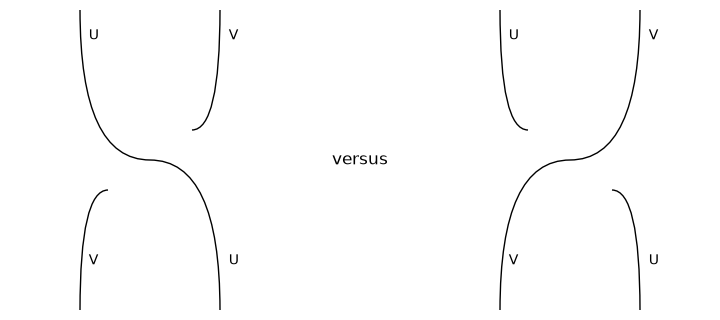

In [1]:
from discopy import braided, ribbon
from discopy.drawing import Equation
U, V, W = map(braided.Ty, ['U', 'V', 'W'])
c_UV = braided.Braid(V, U).dagger()
inverse_c_VU = braided.Braid(U, V)
print('SMSA c_UV:', c_UV.dom, '->', c_UV.cod)
print('SMSA inverse c_VU:', inverse_c_VU.dom, '->', inverse_c_VU.cod)
Equation(c_UV, inverse_c_VU, symbol='versus').draw(figsize=(7,3))
loop = c_UV >> c_UV.dagger()
print('Own inverse cancellation:', loop.simplify(), '; expected:', braided.Id(U @ V))
print('Match:', loop.simplify() == braided.Id(U @ V))

**The strict hexagons.** Use the same crossing convention throughout. A source crossing of $U$ with $V\otimes W$ becomes the inverse of the native crossing of $V\otimes W$ with $U$. `Diagram.braid` expands tensor-word crossings by definition. The tests compare those built-in expansions with the two source crossings, rather than deriving the hexagon from unrelated axioms.

19.39 actual: Braid(V, U)[::-1] @ W >> V @ Braid(W, U)[::-1] expected: Braid(V, U)[::-1] @ W >> V @ Braid(W, U)[::-1] equal: True
19.40 actual: U @ Braid(W, V)[::-1] >> Braid(W, U)[::-1] @ V expected: U @ Braid(W, V)[::-1] >> Braid(W, U)[::-1] @ V equal: True


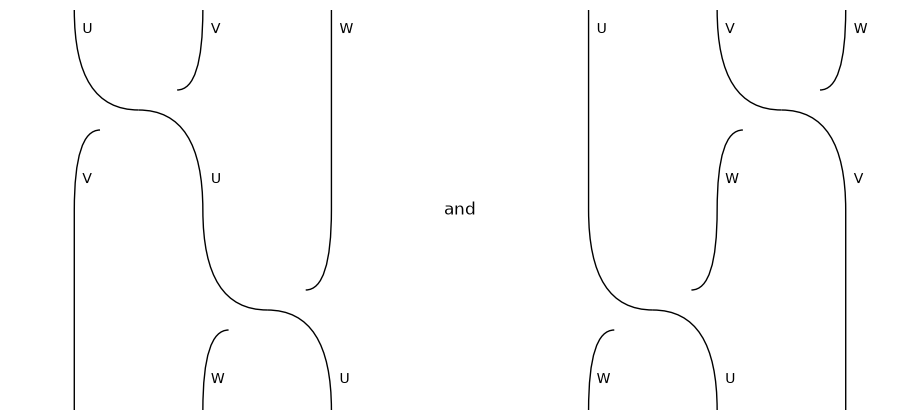

In [2]:
hex_1 = braided.Diagram.braid(V @ W, U).dagger()
hex_1_expanded = (braided.Braid(V,U).dagger() @ braided.Id(W)) >> (braided.Id(V) @ braided.Braid(W,U).dagger())
hex_2 = braided.Diagram.braid(W, U @ V).dagger()
hex_2_expanded = (braided.Id(U) @ braided.Braid(W,V).dagger()) >> (braided.Braid(W,U).dagger() @ braided.Id(V))
for label, actual, expected in [('19.39',hex_1,hex_1_expanded),('19.40',hex_2,hex_2_expanded)]:
    print(label, 'actual:', actual, 'expected:', expected, 'equal:', actual == expected)
Equation(hex_1, hex_2, symbol='and').draw(figsize=(9,4))

**Balancing (19.42): the corresponding ribbon convention.** Reversing the native braiding as above is accompanied by reversing the native twist: encode $\theta_X$ as `Twist(X).dagger()`. This is the mirror ribbon convention, explicitly chosen to retain SMSA's strand-over-strand assignment in the top-down preview. The source puts the twists before both crossings; the inverse of the library's composite twist puts them between crossings. Naturality relates these expressions. The code prints the syntax difference without claiming that `normal_form()` implements naturality.

SMSA ordering: Twist(X)[::-1] @ Y >> X @ Twist(Y)[::-1] >> Braid(Y, X)[::-1] >> Braid(X, Y)[::-1]
Native mirror-twist ordering: Braid(Y, X)[::-1] >> Y @ Twist(X)[::-1] >> Twist(Y)[::-1] @ X >> Braid(X, Y)[::-1]
Boundaries: X @ Y -> X @ Y and X @ Y -> X @ Y
Free syntax equal: False
Normal forms equal: False


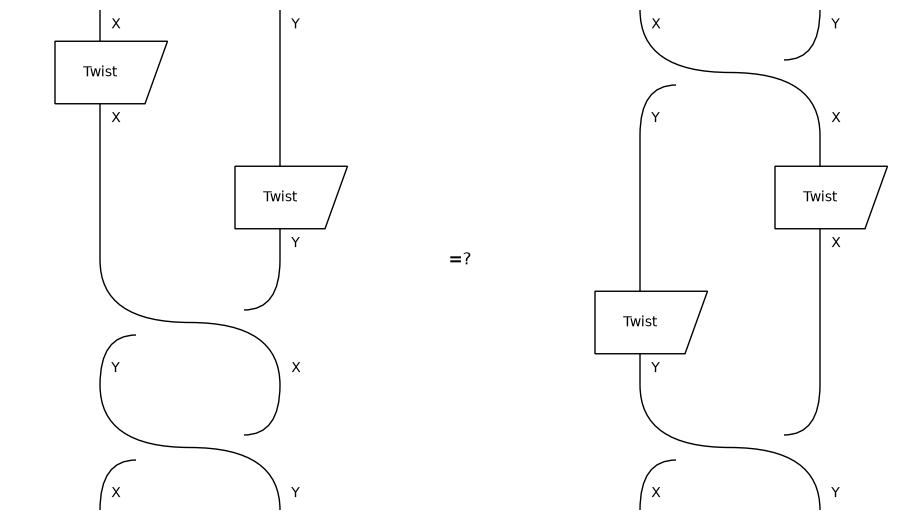

In [3]:
X, Y = ribbon.Ty('X'), ribbon.Ty('Y')
theta_X, theta_Y = ribbon.Twist(X).dagger(), ribbon.Twist(Y).dagger()
c_XY = ribbon.Braid(Y,X).dagger()
c_YX = ribbon.Braid(X,Y).dagger()
smsa_19_42 = (theta_X @ theta_Y) >> c_XY >> c_YX
native_mirror_twist = ribbon.Diagram.twist(X @ Y).dagger()
print('SMSA ordering:', smsa_19_42)
print('Native mirror-twist ordering:', native_mirror_twist)
print('Boundaries:', smsa_19_42.dom, '->', smsa_19_42.cod, 'and', native_mirror_twist.dom, '->', native_mirror_twist.cod)
print('Free syntax equal:', smsa_19_42 == native_mirror_twist)
print('Normal forms equal:', smsa_19_42.normal_form() == native_mirror_twist.normal_form())
Equation(smsa_19_42, native_mirror_twist, symbol='=?').draw(figsize=(9,5))

Naturality gives $(\theta_X\otimes\theta_Y)$ followed by $c_{X,Y}$ equal to $c_{X,Y}$ followed by $(\theta_Y\otimes\theta_X)$. This moves the twists from the source ordering to the native mirror-twist ordering. That is the mathematical justification; the displayed free-diagram comparison is expected to be `False`. The next example supplies a finite graded model and translates ribbon duality (19.43). A gap denotes the under-strand; native dual/twist glyphs remain a converted presentation.

**Ribbon duality (19.43).** The twist on the dual object must equal the dual of the twist: $\theta_{X^\vee}=(\theta_X)^\vee$. The source gives this as a formula (SMSA 7.8, p.440). The following picture is reconstructed from that formula using the duality of §19.5. Both sides act on `X.r`. The right side uses `transpose(left=True)`, the built-in cap–twist–cup composite, which is linear duality, not Hermitian adjoint. We retain the mirror twist convention above. The `=?` records a source axiom: the tested native normal form does not prove it. The option `left=True` matches SMSA (19.32): coevaluation has order `X @ X.r` and evaluation `X.r @ X`. The pivotal type identifies `.l` and `.r`, but the bend order is still chosen from the source.

19.43 twist on dual: Twist(X.r)[::-1] ; boundary: X.r -> X.r
19.43 dual of twist: X.r @ Cap(X, X.r) >> X.r @ Twist(X)[::-1] @ X.r >> Cup(X.r, X) @ X.r ; boundary: X.r -> X.r
Expected boundary: X.r -> X.r
Native normal forms equal: False


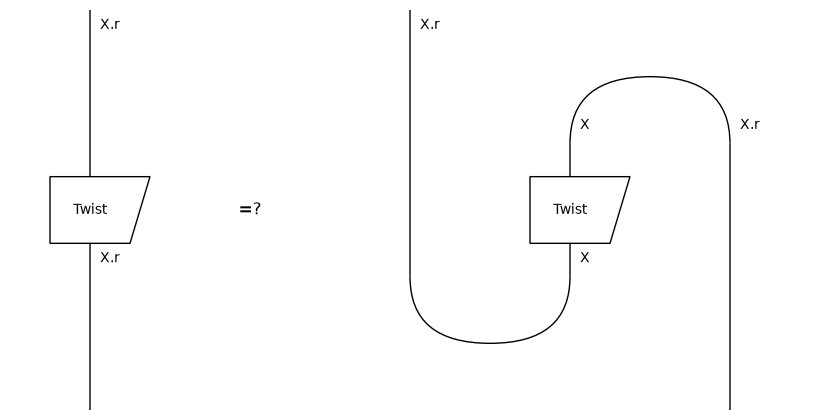

In [4]:
theta_dual = ribbon.Twist(X.r).dagger()
bent_theta = theta_X.transpose(left=True)
print('19.43 twist on dual:', theta_dual, '; boundary:', theta_dual.dom, '->', theta_dual.cod)
print('19.43 dual of twist:', bent_theta, '; boundary:', bent_theta.dom, '->', bent_theta.cod)
print('Expected boundary:', X.r, '->', X.r)
print('Native normal forms equal:', theta_dual.normal_form() == bent_theta.normal_form())
Equation(theta_dual, bent_theta, symbol='=?').draw(figsize=(8,4))

**A chosen graded example.** Choose $X=\mathbb C^3$ with basis $e_0,e_1,e_2$ of degrees $0,1,2$ modulo 3 and $\omega=e^{2\pi i/3}$. This is additional example data, not numbers specified by SMSA. Set
$$c(e_a\otimes e_b)=\omega^{ab}e_b\otimes e_a,\qquad
\theta_X(e_a)=\omega^{a^2}e_a.$$
The dual basis has degrees $0,-1,-2$, so its twist has the same matrix $T=\operatorname{diag}(1,\omega,\omega)$. In contrast, the Hermitian adjoint is $\operatorname{diag}(1,\bar\omega,\bar\omega)$.

A built-in rigid functor evaluates this fragment: cups and caps become the ordinary paired-basis contractions, and the twist/crossing boxes receive the displayed arrays. We explicitly supply their values; this is not a general-purpose graded-category implementation or an automatic proof of the ribbon axioms. The positive native generators receive inverse matrices because our SMSA convention uses their daggers. The values are unitary in these chosen bases, so those daggers evaluate to the desired inverses.

In [5]:
import numpy as np
from discopy import rigid, tensor
omega = np.exp(2j * np.pi / 3)
degrees = np.arange(3)
T = np.diag(omega ** (degrees ** 2 % 3))
T_dual = np.diag(omega ** ((-degrees) ** 2 % 3))
R = np.zeros((3,3,3,3), dtype=complex)
for a in range(3):
    for b in range(3):
        R[a,b,b,a] = omega ** (a*b % 3)
D = tensor.Dim(3)
twist_value = tensor.Tensor[complex](T, D, D)
braid_value = tensor.Tensor[complex](R, D @ D, D @ D)
graded = rigid.Functor(
    ob={X: D},
    ar={ribbon.Twist(X): twist_value.dagger(),
        ribbon.Twist(X.r): tensor.Tensor[complex](T_dual, D, D).dagger(),
        ribbon.Braid(X,X): braid_value.dagger()},
    dom=ribbon.Category(), cod=tensor.Category(tensor.Dim, tensor.Tensor[complex]))
ribbon_actual = graded(theta_dual).array
ribbon_expected = graded(bent_theta).array
print('19.43 twist on dual:\n', ribbon_actual)
print('Cap–twist–cup evaluation:\n', ribbon_expected)
print('Expected ordinary transpose T^t:\n', T.T)
print('Equal within 1e-12:', np.allclose(ribbon_actual, ribbon_expected, atol=1e-12, rtol=0))
wrong_adjoint = graded(theta_X.dagger()).array
print('Control: Hermitian adjoint instead:\n', wrong_adjoint)
print('Matches dual twist (expected False):', np.allclose(ribbon_actual, wrong_adjoint, atol=1e-12, rtol=0))

19.43 twist on dual:
 [[ 1. +0.j         0. +0.j         0. +0.j       ]
 [ 0. +0.j        -0.5+0.8660254j  0. +0.j       ]
 [ 0. +0.j         0. +0.j        -0.5+0.8660254j]]
Cap–twist–cup evaluation:
 [[ 1. +0.j         0. +0.j         0. +0.j       ]
 [ 0. +0.j        -0.5+0.8660254j  0. +0.j       ]
 [ 0. +0.j         0. +0.j        -0.5+0.8660254j]]
Expected ordinary transpose T^t:
 [[ 1. +0.j         0. +0.j         0. +0.j       ]
 [ 0. +0.j        -0.5+0.8660254j  0. +0.j       ]
 [ 0. +0.j         0. +0.j        -0.5+0.8660254j]]
Equal within 1e-12: True
Control: Hermitian adjoint instead:
 [[ 1. -0.j         0. -0.j         0. -0.j       ]
 [ 0. -0.j        -0.5-0.8660254j  0. -0.j       ]
 [ 0. -0.j         0. -0.j        -0.5-0.8660254j]]
Matches dual twist (expected False): False


**Check the chosen data.** For basis degrees $a,b$, (19.42) predicts the tensor-product twist $\omega^{(a+b)^2}$. We evaluate its source composite and the native composite twist on all nine basis pairs. The phase rule for the braiding is checked on all 27 triples. These finite tests support this example; they do not turn a failed free-diagram comparison into a general rewrite.

In [6]:
c_XX = ribbon.Braid(X,X).dagger()
balancing_XX = (theta_X @ theta_X) >> c_XX >> c_XX
balancing_actual = graded(balancing_XX).array.reshape(9,9)
balancing_expected = np.diag([omega ** ((a+b)**2 % 3) for a in range(3) for b in range(3)])
print('19.42 tensor-twist diagonal, actual:', np.diag(balancing_actual))
print('Expected by total degree:', np.diag(balancing_expected))
print('Full 9 by 9 arrays equal:', np.allclose(balancing_actual, balancing_expected, atol=1e-12, rtol=0))
print('Native mirror twist agrees:', np.allclose(graded(ribbon.Diagram.twist(X @ X).dagger()).array.reshape(9,9), balancing_expected, atol=1e-12, rtol=0))
phase_residuals = np.array([
    [omega**(a*((b+c)%3)%3) - omega**(a*b%3)*omega**(a*c%3),
     omega**(((a+b)%3)*c%3) - omega**(a*c%3)*omega**(b*c%3)]
    for a in range(3) for b in range(3) for c in range(3)])
print('Two phase laws on 27 triples; maximum residual:', np.max(np.abs(phase_residuals)), '; expected: 0')
print('Within 1e-12:', np.allclose(phase_residuals, 0, atol=1e-12, rtol=0))
trace_twist = graded(c_XX.trace()).array
print("Partial trace of crossing:\n", trace_twist, "; expected twist:\n", T)
print("Trace gives twist:", np.allclose(trace_twist, T, atol=1e-12, rtol=0))


19.42 tensor-twist diagonal, actual: [ 1. +0.00000000e+00j -0.5+8.66025404e-01j -0.5+8.66025404e-01j
 -0.5+8.66025404e-01j -0.5+8.66025404e-01j  1. -8.88178420e-16j
 -0.5+8.66025404e-01j  1. -8.88178420e-16j -0.5+8.66025404e-01j]
Expected by total degree: [ 1. +0.j        -0.5+0.8660254j -0.5+0.8660254j -0.5+0.8660254j
 -0.5+0.8660254j  1. +0.j        -0.5+0.8660254j  1. +0.j
 -0.5+0.8660254j]
Full 9 by 9 arrays equal: True
Native mirror twist agrees: True
Two phase laws on 27 triples; maximum residual: 5.703597753175952e-16 ; expected: 0
Within 1e-12: True
Partial trace of crossing:
 [[ 1. +0.j         0. +0.j         0. +0.j       ]
 [ 0. +0.j        -0.5+0.8660254j  0. +0.j       ]
 [ 0. +0.j         0. +0.j        -0.5+0.8660254j]] ; expected twist:
 [[ 1. +0.j         0. +0.j         0. +0.j       ]
 [ 0. +0.j        -0.5+0.8660254j  0. +0.j       ]
 [ 0. +0.j         0. +0.j        -0.5+0.8660254j]]
Trace gives twist: True


**Scope and library detail.** The general ribbon-duality equation is now drawn and the supplied graded example evaluates it. A general native rewrite remains unavailable in the tested normal form. In DisCoPy 1.2.2, `theta_X.r` retains boundary `X -> X`; it is therefore not used for the source dual map. Explicit `transpose(left=True)` has the required `X.r -> X.r` boundary. The numeric interpretation checks this diagram without relying on that rotation shortcut. No tensor model of the full Ising category is implied.